<a href="https://colab.research.google.com/github/valegio/MapaRelaveCL/blob/main/C2M5_practice_set.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Before you start

First, be sure to **save a copy of this notebook to google drive**, so that your work is saved in your personal drive as you work. **Delete the "copy of"**, so that the file name remains the same as it was originally named.

Second, Google Colab defaults to a Python runtime. Because this problem set is written in R, you need to switch the runtime once before running any code:

1. In the Colab menu bar, click **Runtime → Change runtime type**.
2. Under **Runtime type**, select **R**.
3. Click **Save**. Colab will reload the notebook with R.

You only need to do this once per Colab session. After switching, run the next cell to install the R packages you'll need.


## Data Stewardship -- Problem Set 5: Efficient Coding and Data Manipulation in R
In this problem set, you will clean the raw air quality measurement from the `example_air_quality.csv` dataset, join them with additional information about each monitoring station, and analyze difference in PM2.5 concentrations across the locations. Recall from lecture that the CSV contains the following variables:

    - timestamp: the date and time of each measurement
    - location: the monitoring site (North, South, East, or West Station)
    - temperature_C: temperature in degrees Celsius
    - humidity_percent: relative humidity (%)
    - pm25: fine particulate matter concentration (µg/m³)
    - no2_ppb: nitrogen dioxide (parts per billion)
    - ozone_ppb: ozone (parts per billion)


Throughout this problem set, be sure to include comments with meaningful descriptions for each step.

As always, use sources like Google, Stack Overflow, documentation, and other forums for help. Try to avoid AI in order to develop your own ability to conceptualize solution strategies.

## Question 0: Reading Data from a Raw GitHub Link

Before working with your data, you need to get it into R. In this problem set the air quality data lives in a **GitHub repository** — the same one you cloned to get this notebook. Rather than worrying about file paths and working directories, we'll read the CSV straight from its **raw GitHub link**.

A *raw* GitHub link points directly to the contents of a file (the actual text of the CSV), rather than to the GitHub webpage that displays it. In R, `read.csv()` can take a URL anywhere it would take a file path, so you can hand it a raw link and it will download and parse the CSV file for you.

We've filled in this question for you so you can see the workflow. Read through each step and run the cells so you understand what's happening — you'll use this same approach in Question 1.

1. We store the raw GitHub link to `example_air_quality.csv` in a variable called `data_url`. Assigning the URL to a well-named variable keeps the rest of your code clean and readable. (Run the cell to see the link.)

2. We pass `data_url` to `read.csv()` to download and read the file into a dataframe called `preview_df`, then use `head()` to peek at the first few rows and confirm it loaded correctly.

> **Why this matters:** because you read the data from a public URL, your code will run anywhere without you needing to set a working directory or track where the file lives on disk. In Question 1 you'll reuse this same `data_url` to import the data yourself.


In [1]:
# Load libraries
library(tidyverse)   # For data manipulation and visualization

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
# store the raw GitHub link to the data file in a well-named variable
data_url <- "https://raw.githubusercontent.com/yse-eds-cert/practice-set-5/main/data/example_air_quality.csv"
data_url


[1] "https://raw.githubusercontent.com/yse-eds-cert/practice-set-5/main/data/example_air_quality.csv"

In [3]:
# read the CSV directly from the raw GitHub link and preview the first few rows
preview_df <- read.csv(data_url)
head(preview_df)


,timestamp,location,temperature_C,humidity_percent,pm25,no2_ppb,ozone_ppb
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7/1/23 0:00,West Station,23.5,45.8,14.5,16.7,17.2
2,7/1/23 1:00,East Station,21.6,55.8,15.9,19.4,25.2
3,7/1/23 2:00,North Station,23.9,NA,19.6,32.5,30.0
4,7/1/23 3:00,North Station,26.6,52.0,19.4,31.1,30.4
5,7/1/23 4:00,West Station,21.3,58.4,2.4,24.8,26.4
6,7/1/23 5:00,North Station,21.3,64.0,5.4,26.2,35.0


## Question 1: Code Organization

Start your notebook by setting it up in a clean and organized way with clear, descriptive naming:

1. Load the relevant libraries for data cleaning and visualization.
2. Import `example_air_quality.csv` by reading it from the raw GitHub link, just like we did in Question 0.
   - You can reuse the `data_url` variable you saw in Question 0, or paste the raw link directly into `read.csv()`. Either way, save the result in a dataframe called `air_quality_df`.
3. Inspect the dataset to refresh your memory of its variables and data types.

Recall from your lecture videos this week: what was the main problem Mitch discussed with respect to the `example_air_quality.csv` dataset?

4. Create a new cleaned dataframe that:
   - Fixes this problem for the `pm25` or `timestamp` columns (it should take no longer than 2-3 lines of code), and
   - Converts the `timestamp` column from a character string into a proper date/datetime format using `mutate(timestamp = as.POSIXct(timestamp, format = "%m/%d/%y %H:%M"))`

Recall from Data Foundations last week that `mutate()` is the tidyverse function for creating a new column in your dataset.

Feel free to use additional sources to learn more about date and datetime formats in R: https://stat.ethz.ch/R-manual/R-devel/library/base/html/as.POSIXlt.html.


In [5]:
# ✏️ load libraries
library(tidyverse)
library(ggplot2)

In [7]:
# ✏️ import data from the raw GitHub link
air_quality_df <- read.csv("https://raw.githubusercontent.com/yse-eds-cert/yse-eds-cert-practice-set-5-valegio/refs/heads/main/data/example_air_quality.csv?token=GHSAT0AAAAAAEPE32TPO4X2NGWUSBHRHN7G2XM7YFA")

In [15]:
# ✏️ inspect the data
head(air_quality_df)

,timestamp,location,temperature_C,humidity_percent,pm25,no2_ppb,ozone_ppb
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7/1/23 0:00,West Station,23.5,45.8,14.5,16.7,17.2
2,7/1/23 1:00,East Station,21.6,55.8,15.9,19.4,25.2
3,7/1/23 2:00,North Station,23.9,NA,19.6,32.5,30.0
4,7/1/23 3:00,North Station,26.6,52.0,19.4,31.1,30.4
5,7/1/23 4:00,West Station,21.3,58.4,2.4,24.8,26.4
6,7/1/23 5:00,North Station,21.3,64.0,5.4,26.2,35.0


In [49]:
# ✏️ clean data
clean_AQ_df <- air_quality_df %>%
      # Fix problem for pm25 and timestamp columns
      filter(!is.na(pm25) & (timestamp != '')) %>%
      # convert timestamp column
      # mutate(timestamp=as.Date(timestamp, format= "%d/%m/%Y"))
      mutate(timestamp = as.POSIXct(timestamp, format = "%m/%d/%y %H:%M"))
head(clean_AQ_df)

sum = summary(clean_AQ_df)
sum

,timestamp,location,temperature_C,humidity_percent,pm25,no2_ppb,ozone_ppb
,<dttm>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2023-07-01 00:00:00,West Station,23.5,45.8,14.5,16.7,17.2
2,2023-07-01 01:00:00,East Station,21.6,55.8,15.9,19.4,25.2
3,2023-07-01 02:00:00,North Station,23.9,NA,19.6,32.5,30.0
4,2023-07-01 03:00:00,North Station,26.6,52.0,19.4,31.1,30.4
5,2023-07-01 04:00:00,West Station,21.3,58.4,2.4,24.8,26.4
6,2023-07-01 05:00:00,North Station,21.3,64.0,5.4,26.2,35.0


   timestamp                        location  temperature_C   humidity_percent
 Min.   :2023-07-01 00:00:00   Length   :93   Min.   :16.00   Min.   :40.80   
 1st Qu.:2023-07-02 00:00:00   N.unique : 4   1st Qu.:20.20   1st Qu.:51.73   
 Median :2023-07-03 00:00:00   N.blank  : 0   Median :21.40   Median :60.65   
 Mean   :2023-07-03 00:36:46   Min.nchar:12   Mean   :21.72   Mean   :59.90   
 3rd Qu.:2023-07-04 01:00:00   Max.nchar:13   3rd Qu.:23.50   3rd Qu.:65.08   
 Max.   :2023-07-05 03:00:00                  Max.   :27.60   Max.   :87.20   
                                              NAs    :4       NAs    :5       
      pm25          no2_ppb        ozone_ppb   
 Min.   : 0.70   Min.   : 3.80   Min.   :11.6  
 1st Qu.: 7.40   1st Qu.:19.20   1st Qu.:22.4  
 Median :12.50   Median :25.20   Median :29.5  
 Mean   :12.44   Mean   :25.89   Mean   :29.4  
 3rd Qu.:16.80   3rd Qu.:31.80   3rd Qu.:35.2  
 Max.   :28.20   Max.   :46.90   Max.   :54.6  
                                

## Question 2: Creating a Metadata Table for Joins

Now, we have a cleaned dataset with PM2.5 measurements at the four monitoring stations, but those values alone don’t explain why air quality might differ from place to place. To better interpret the data, we need more information about the stations themselves.

First, we’ll assign each station a site type to describe its surrounding environment:

    - North Station → Urban
    - South Station → Near-road
    - West Station → Suburban
    - East Station → Waterfront


Second, air quality monitors can sometimes give measurements that are different from the true PM2.5 concentration in the air. Small differences in the type of sensor, how old it is, or how well it has been maintained can affect the numbers it reports.

To make the data comparable across locations, researchers often apply calibration factors. A calibration factor is a simple multiplier that adjusts each monitor’s readings, so they are more consistent with a trusted baseline.

For example, if a sensor tends to read 5% too high, a calibration factor of ~0.95 (1.00/1.05) will scale it down. If a sensor reads a bit too low, perhaps 97% of the true value, a factor near 1.03 (1.00/0.97) will scale it up. These adjustments make values across sites more directly comparable.

For our four stations, we’ll use the following sample calibration factors:

    - North Station → 0.98 (slightly high, scaled down 2%)
    - South Station → 1.03 (slightly low, scaled up 3%)
    - West Station → 1.00 (well calibrated, no adjustment)
    - East Station → 1.05 (reads low, scaled up 5%)

Now, create a dataframe called `site_meta` containing three columns with clear, descriptive names corresponding to

    - Location (station name - make sure you use the exact same text for both column name and column values as your cleaned data frame from Q1!)
    - Site Type (as listed above)
    - Calibration Factor (as listed above)

Make sure your dataframe has the rows and columns in the exact order above, otherwise you may not receive credit for your answer.

Lastly, print the `site_meta` dataframe.

In [53]:
# ✏️ create a dataframe
site_meta <- data.frame(
  location = c("North Station", "South Station", "West Station", "East Station"),
  site_type = c("Urban", "Near-road", "Suburban", "Waterfront"),
  calibration_factor = c(0.98, 1.03, 1.00, 1.05)
)

# print the dataframe
site_meta


location,site_type,calibration_factor
<chr>,<chr>,<dbl>
North Station,Urban,0.98
South Station,Near-road,1.03
West Station,Suburban,1.00
East Station,Waterfront,1.05


## Question 3: Joins

Now that you have created the `site_meta` table, we want to join it with your cleaned air quality data.

1. What is the field or column can act as a unique key to join the two data frames? Save that column's name in your cleaned dataset in an object called `unique_key`.
2. Use a `left_join()` to combine your cleaned air quality dataframe with the `site_meta` dataframe. Save the result as a new dataframe called `complete_AQ` (i.e. a clear, descriptive name).
3. Create a new column called `pm25_adj` that multiplies the raw pm25 values by the station’s calibration factor.
4. Print the first 10 rows to check that the join worked correctly.

In [55]:
# ✏️ Uncomment the line of code below and store your answer for 1.
unique_key <- "location"

In [58]:
# ✏️ Combine cleaned df with site_meta
complete_AQ  <- left_join(x=clean_AQ_df, y=site_meta, by=unique_key)
head(complete_AQ)

# Create new column
complete_AQ$pm25_adj <- complete_AQ$pm25 * complete_AQ$calibration_factor


,timestamp,location,temperature_C,humidity_percent,pm25,no2_ppb,ozone_ppb,site_type,calibration_factor
,<dttm>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
1,2023-07-01 00:00:00,West Station,23.5,45.8,14.5,16.7,17.2,Suburban,1.00
2,2023-07-01 01:00:00,East Station,21.6,55.8,15.9,19.4,25.2,Waterfront,1.05
3,2023-07-01 02:00:00,North Station,23.9,NA,19.6,32.5,30.0,Urban,0.98
4,2023-07-01 03:00:00,North Station,26.6,52.0,19.4,31.1,30.4,Urban,0.98
5,2023-07-01 04:00:00,West Station,21.3,58.4,2.4,24.8,26.4,Suburban,1.00
6,2023-07-01 05:00:00,North Station,21.3,64.0,5.4,26.2,35.0,Urban,0.98


In [59]:
# ✏️ Print the first 10 rows
head(complete_AQ, 10)

,timestamp,location,temperature_C,humidity_percent,pm25,no2_ppb,ozone_ppb,site_type,calibration_factor,pm25_adj
,<dttm>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>
1,2023-07-01 00:00:00,West Station,23.5,45.8,14.5,16.7,17.2,Suburban,1.00,14.500
2,2023-07-01 01:00:00,East Station,21.6,55.8,15.9,19.4,25.2,Waterfront,1.05,16.695
3,2023-07-01 02:00:00,North Station,23.9,NA,19.6,32.5,30.0,Urban,0.98,19.208
4,2023-07-01 03:00:00,North Station,26.6,52.0,19.4,31.1,30.4,Urban,0.98,19.012
5,2023-07-01 04:00:00,West Station,21.3,58.4,2.4,24.8,26.4,Suburban,1.00,2.400
6,2023-07-01 05:00:00,North Station,21.3,64.0,5.4,26.2,35.0,Urban,0.98,5.292
7,2023-07-01 06:00:00,North Station,NA,78.9,15.6,37.8,21.5,Urban,0.98,15.288
8,2023-07-01 07:00:00,West Station,24.3,61.7,15.6,19.1,28.9,Suburban,1.00,15.600
9,2023-07-01 08:00:00,South Station,20.6,NA,15.6,30.5,31.0,Near-road,1.03,16.068


## Question 4: Pivots

### Part A
Now, we want to see how air quality changes over the course of a typical day at each station. To do this, we want to average the adjusted PM2.5 values by hour for each station, then pivot to a wide format so each location becomes its own column. Pivoting to wide format then lets us look at all four stations side by side, making it easier to compare their daily patterns directly.

1. Create an hour variable in your joined dataframe using `hour = lubridate::hour(timestamp)`. (Note: `hour()` extracts the hour of the day as an integer from 0 to 23)
2. Create a new dataframe, `hourly_pm25_avg`, that calculates the hourly average adjusted PM2.5 (`pm25_adj`) at each location. (Hint: group by hour and location, then summarise with `mean(pm25_adj, na.rm=TRUE)` to compute the averages)
3. Convert this hourly summary dataframe into wide format using `tidyr::pivot_wider()`. Name the new dataframe `hourly_pm25_wide` (i.e. a clear, descriptive name); it should have one row per hour and one column for each location, with the values filled in from the hourly averages you calculated in Step 2.
4. Print the first 10 rows of your wide format dataframe and confirm the following columns: `hour`, `East Station`, `North Station`, `South Station`, `West Station`.



In [71]:
# ✏️ Create hour variable
complete_AQ$hour <- lubridate::hour(complete_AQ$timestamp)
head(complete_AQ)

,timestamp,location,temperature_C,humidity_percent,pm25,no2_ppb,ozone_ppb,site_type,calibration_factor,pm25_adj,hour
,<dttm>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<int>
1,2023-07-01 00:00:00,West Station,23.5,45.8,14.5,16.7,17.2,Suburban,1.00,14.500,0
2,2023-07-01 01:00:00,East Station,21.6,55.8,15.9,19.4,25.2,Waterfront,1.05,16.695,1
3,2023-07-01 02:00:00,North Station,23.9,NA,19.6,32.5,30.0,Urban,0.98,19.208,2
4,2023-07-01 03:00:00,North Station,26.6,52.0,19.4,31.1,30.4,Urban,0.98,19.012,3
5,2023-07-01 04:00:00,West Station,21.3,58.4,2.4,24.8,26.4,Suburban,1.00,2.400,4
6,2023-07-01 05:00:00,North Station,21.3,64.0,5.4,26.2,35.0,Urban,0.98,5.292,5


In [66]:
# ✏️ Create a new dataframe
hourly_pm25_avg <- complete_AQ %>%
  group_by(hour, location) %>%
  summarise(
  hr_pm25_avg = mean(pm25_adj, na.rm=TRUE)
  )

head(hourly_pm25_avg)

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by hour and location.
ℹ Output is grouped by hour.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(hour, location))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


hour,location,hr_pm25_avg
<int>,<chr>,<dbl>
0,North Station,20.9230
0,South Station,8.9610
0,West Station,17.3000
1,East Station,16.1175
1,South Station,12.4630
2,North Station,19.2080


In [72]:
# ✏️ Convert to wide format
hourly_pm25_wide <- hourly_pm25_avg %>%
  pivot_wider(names_from = location, values_from = hr_pm25_avg)

head(hourly_pm25_wide)

hour,North Station,South Station,West Station,East Station
<int>,<dbl>,<dbl>,<dbl>,<dbl>
0,20.92300,8.961,17.3,NA
1,NA,12.463,NA,16.1175
2,19.20800,NA,7.8,NA
3,17.70533,NA,4.5,15.9600
4,NA,27.707,4.7,14.0700
5,5.29200,19.776,NA,12.9150


In [73]:
# ✏️ Print the first 10 rows
head(hourly_pm25_wide, 10)

hour,North Station,South Station,West Station,East Station
<int>,<dbl>,<dbl>,<dbl>,<dbl>
0,20.92300,8.961,17.3,NA
1,NA,12.463,NA,16.1175
2,19.20800,NA,7.8,NA
3,17.70533,NA,4.5,15.9600
4,NA,27.707,4.7,14.0700
5,5.29200,19.776,NA,12.9150
6,15.28800,12.875,NA,4.3575
7,8.42800,NA,12.8,NA
8,12.54400,16.068,20.9,12.9150


### Part B

Provide 1-2 sentences describing any patterns you notice in PM2.5 concentrations during the first 10 hours of the day. This can include differences between stations or changes from midnight through the morning. **Keep your answer brief; it should not exceed 1 line if possible.**

*✏️ Write your answer here.*

South station shows the highest concentration of PM25 registered (27.7 µg/m³, 4:00), while North and West stations show a similar maxima (20.9 µg/m³), the first at 0:00 and the second at 8:00.

## Question 5: Plotting from Pivoted Data

### Part A

Now, we want to visualize these patterns using line charts.

Using the pivoted dataframe from Question 4:

1. Convert the wide dataframe back into long format using `tidyr::pivot_longer()`. (See more information on `pivot_longer()` [here](https://cran.r-project.org/web/packages/tidyr/vignettes/pivot.html).) Call the new dataframe `hourly_pm25_long`. In the new dataframe, call the column holding the station names `location` and the column holding the values called `pm25_hourly`. This will take the four separate station columns and stack them into a single location column paired with their corresponding PM2.5 measurements.

2. Create a bar chart of the hourly mean adjusted PM2.5 at each location and overlay a smoothed trend line. Save the chart in an object called `my_plot`.
- Use `ggplot2::geom_col()` for the bars and add `ggplot2::geom_smooth()` for the trend line
- Create four subplots (one per location), using `ggplot2::facet_wrap(~location)`
- x-axis: hour (0–23)
- y-axis: hourly average PM2.5 (adjusted, µg/m³)
- Include clear axis labels and a descriptive title

hour,location,pm25_hourly
<int>,<chr>,<dbl>
0,North Station,20.923
0,South Station,8.961
0,West Station,17.300
0,East Station,NA
1,North Station,NA
1,South Station,12.463


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'
Warning message:
“Removed 35 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 35 rows containing missing values or values outside the scale range
(`geom_col()`).”


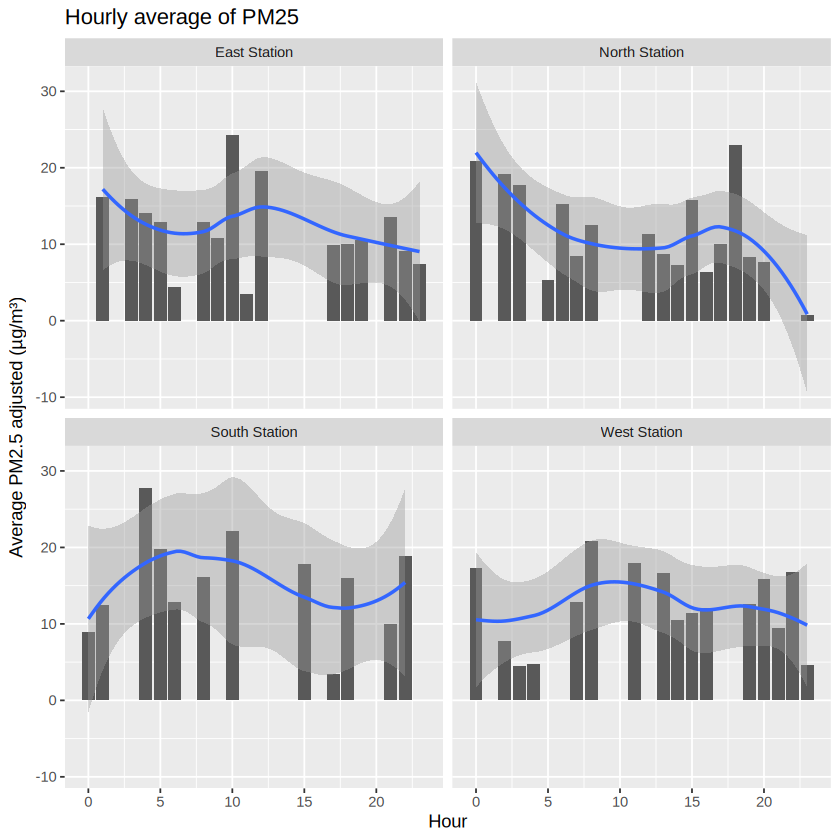

In [82]:
# ✏️ Convert wide dataframe back to long
hourly_pm_long <- hourly_pm25_wide %>%
  pivot_longer(
    cols = c("North Station", "South Station", "West Station", "East Station"),
    names_to = "location",
    values_to = "pm25_hourly")
head(hourly_pm_long)

# Create bar chart
my_plot <- ggplot(hourly_pm_long, aes(x=hour, y=pm25_hourly, ymin=0)) +
  geom_col() +
  geom_smooth() +
  facet_wrap(~location) +
  labs(title= "Hourly average of PM25",
  x= "Hour",
  y= "Average PM2.5 adjusted (µg/m³)")
my_plot

### Part B

Provide 1-2 sentences that describe any noticeable patterns, trends, or other key observations in the line charts. **Keep your answer brief; it should not exceed 1 line if possible.**

*✏️ Write your answer here.*

The North station has two peak concentrations, at 00:00 and at 18:00.

---

## How to submit

When you've finished the problem set:

1. In the Colab menu bar, click **File → Save a copy in GitHub**.
2. In the dialog:
   - **Repository**: choose the repository Classroom50 created for you when you accepted this assignment (it will have your GitHub username in the name).
   - **Branch**: `main`.
   - **File path**: leave the filename as-is so it overwrites the starter notebook.
   - **Commit message**: something descriptive, e.g. *"Finished pset"*.
3. Be sure to click **"Include a link to colab",** please!
3. Click **OK**. Colab will push your completed notebook back to your assignment repository.

You can save to GitHub as often as you like — each save is just another commit. Your most recent commit before the due date is what gets graded.
